In [1]:
!pip install -q pyspark
import pandas as pd, numpy as np, time, random
print("Installed")

Installed


In [2]:
import numpy as np, pandas as pd, os, time

os.makedirs("data", exist_ok=True)

PLATFORMS = ["Facebook", "Instagram", "Google", "TikTok", "YouTube"]
PLAT_P = [0.24, 0.30, 0.20, 0.14, 0.12]
CTR = np.array([0.012, 0.014, 0.022, 0.017, 0.007])
CPM = np.array([380, 420, 800, 260, 320])
CVR = np.array([0.025, 0.034, 0.028, 0.015, 0.016])
AOV = np.array([6500, 7800, 7000, 4800, 6000])

CAMPAIGNS = ["Lawn Collection", "Eid Collection", "Winter Collection", "Summer Sale",
             "Mid-Season Sale", "Independence Day Sale", "Black Friday",
             "Bridal and Festive", "Khaadi Home"]
CAMP_CTR = np.array([1.3, 1.3, 1.1, 1.2, 1.1, 1.1, 1.2, 1.0, 0.8])
CAMP_CVR = np.array([1.4, 1.5, 1.2, 1.3, 1.2, 1.2, 1.4, 1.1, 0.8])

CITIES = ["Karachi", "Lahore", "Islamabad", "Rawalpindi", "Faisalabad", "Multan", "Peshawar", "Quetta"]
CITY_P = np.array([0.25, 0.27, 0.14, 0.07, 0.08, 0.07, 0.07, 0.05])
CITY_CVR = np.array([1.00, 1.05, 1.10, 0.95, 0.90, 0.85, 0.85, 0.75])

DEVICES = ["Mobile", "Desktop", "Tablet"]
DEV_P = [0.78, 0.15, 0.07]
DEV_CVR = np.array([0.95, 1.20, 1.00])

AGES = ["18-24", "25-34", "35-44", "45-54", "55+"]
AGE_CVR = np.array([0.95, 1.15, 1.10, 1.00, 0.90])
AGE_P = np.array([
    [0.14, 0.30, 0.27, 0.17, 0.12],
    [0.34, 0.38, 0.17, 0.08, 0.03],
    [0.18, 0.36, 0.26, 0.13, 0.07],
    [0.58, 0.27, 0.09, 0.04, 0.02],
    [0.24, 0.33, 0.22, 0.13, 0.08],
])

DAY_CVR = np.array([1.00, 1.00, 1.00, 1.00, 1.10, 1.05, 1.05])  # Friday boost (Project 1 finding)

def generate(n, seed=42):
    rng = np.random.default_rng(seed)
    p = rng.choice(5, n, p=PLAT_P)
    c = rng.integers(0, len(CAMPAIGNS), n)
    ci = rng.choice(len(CITIES), n, p=CITY_P)
    d = rng.choice(3, n, p=DEV_P)
    g = rng.choice(["Female", "Male"], n, p=[0.68, 0.32])
    a = np.zeros(n, dtype=int)
    for i in range(5):
        m = p == i
        a[m] = rng.choice(5, m.sum(), p=AGE_P[i])

    dates = pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 638, n), unit="D")
    dow = dates.dayofweek.to_numpy()

    imp = rng.lognormal(np.log(25000), 0.8, n).astype(np.int64) + 100
    ctr = CTR[p] * CAMP_CTR[c] * rng.lognormal(0, 0.15, n)
    cvr = (CVR[p] * CAMP_CVR[c] * CITY_CVR[ci] * DEV_CVR[d] * AGE_CVR[a]
           * DAY_CVR[dow] * rng.lognormal(0, 0.15, n))

    clicks = rng.binomial(imp, np.clip(ctr, 0, 1))
    conv = rng.binomial(clicks, np.clip(cvr, 0, 1))
    spend = imp / 1000 * CPM[p] * rng.lognormal(0, 0.10, n)
    revenue = conv * AOV[p] * rng.lognormal(0, 0.20, n)

    return pd.DataFrame({
        "date": dates.to_numpy(),
        "campaign": np.array(CAMPAIGNS)[c],
        "platform": np.array(PLATFORMS)[p],
        "impressions": imp,
        "clicks": clicks,
        "spend": spend.round(2),
        "conversions": conv,
        "revenue": revenue.round(2),
        "age": np.array(AGES)[a],
        "gender": g,
        "city": np.array(CITIES)[ci],
        "device": np.array(DEVICES)[d],
    })

print("Generator ready")

Generator ready


In [3]:
for n in [10_000, 100_000, 1_000_000]:
    generate(n, seed=n + 7).to_csv(f"data/ads_{n}.csv", index=False, date_format="%Y-%m-%d")
    print(f"{n:,} records done")

path = "data/ads_10000000.csv"
if os.path.exists(path):
    os.remove(path)
t = time.time()
for i in range(10):
    part = generate(1_000_000, seed=1000 + i)
    part.to_csv(path, mode="a", header=(i == 0), index=False, date_format="%Y-%m-%d")
    print(f"10M chunk {i+1}/10 | {time.time()-t:.0f} sec")
    del part
print("All data files ready")

10,000 records done
100,000 records done
1,000,000 records done
10M chunk 1/10 | 16 sec
10M chunk 2/10 | 29 sec
10M chunk 3/10 | 43 sec
10M chunk 4/10 | 62 sec
10M chunk 5/10 | 90 sec
10M chunk 6/10 | 106 sec
10M chunk 7/10 | 119 sec
10M chunk 8/10 | 133 sec
10M chunk 9/10 | 146 sec
10M chunk 10/10 | 159 sec
All data files ready


In [4]:
df = pd.read_csv("data/ads_100000.csv", parse_dates=["date"])

def add_kpis(t):
    t = t.copy()
    t["CTR_%"] = t.clicks / t.impressions * 100
    t["CPC"] = t.spend / t.clicks.replace(0, np.nan)
    t["CPA"] = t.spend / t.conversions.replace(0, np.nan)
    t["ConvRate_%"] = t.conversions / t.clicks.replace(0, np.nan) * 100
    t["ROAS"] = t.revenue / t.spend
    t["Profit"] = t.revenue - t.spend
    return t

def summarize(data, by):
    g = data.groupby(by)[["impressions", "clicks", "spend", "conversions", "revenue"]].sum()
    return add_kpis(g).round(2)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 200

df = add_kpis(df)
tot = add_kpis(df[["impressions", "clicks", "spend", "conversions", "revenue"]].sum().to_frame().T)
print("OVERALL (100,000 records)")
print(tot[["CTR_%", "CPC", "CPA", "ConvRate_%", "ROAS"]].round(2).to_string(index=False))

platform_kpi = summarize(df, "platform").sort_values("ROAS", ascending=False)
campaign_kpi = summarize(df, "campaign").sort_values("ROAS", ascending=False)
print("\nPLATFORM PERFORMANCE")
print(platform_kpi[["CTR_%", "CPC", "CPA", "ConvRate_%", "ROAS"]])
print("\nCAMPAIGN PERFORMANCE")
print(campaign_kpi[["CTR_%", "CPC", "CPA", "ConvRate_%", "ROAS"]])
platform_kpi.to_csv("platform_kpi.csv")
campaign_kpi.to_csv("campaign_kpi.csv")

df["day"] = df.date.dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
for dim in ["city", "device", "age", "gender"]:
    print(f"\nBY {dim.upper()}")
    print(summarize(df, dim).sort_values("ROAS", ascending=False)[["CTR_%", "CPC", "CPA", "ConvRate_%", "ROAS"]])
print("\nBY DAY OF WEEK")
print(summarize(df, "day").reindex(order)[["CTR_%", "CPC", "CPA", "ConvRate_%", "ROAS"]])

OVERALL (100,000 records)
 CTR_%   CPC    CPA  ConvRate_%  ROAS
  1.67 27.12 766.18        3.54  9.27

PLATFORM PERFORMANCE
           CTR_%   CPC      CPA  ConvRate_%  ROAS
platform                                         
Instagram   1.59 26.53   579.56        4.58 13.72
Google      2.51 32.04   844.99        3.79  8.44
Facebook    1.36 28.05   833.92        3.36  7.94
TikTok      1.94 13.51   694.70        1.94  7.01
YouTube     0.79 40.49 1,878.27        2.16  3.26

CAMPAIGN PERFORMANCE
                       CTR_%   CPC      CPA  ConvRate_%  ROAS
campaign                                                     
Eid Collection          1.93 23.42   557.45        4.20 12.78
Lawn Collection         1.94 23.48   598.32        3.92 11.79
Black Friday            1.80 25.39   646.68        3.93 10.94
Summer Sale             1.79 25.38   696.01        3.65 10.26
Mid-Season Sale         1.64 27.51   812.65        3.39  8.75
Winter Collection       1.64 27.73   817.98        3.39  8.74
Independ

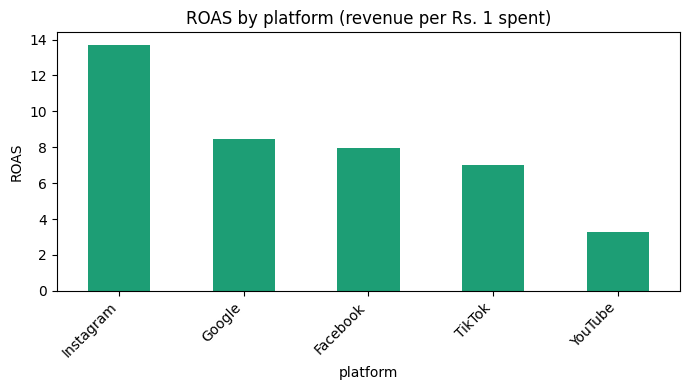

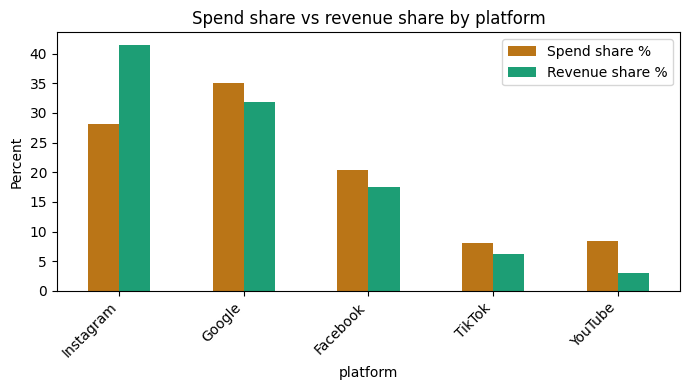

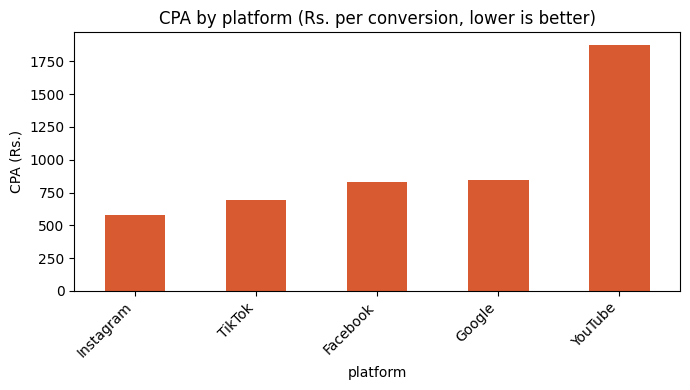

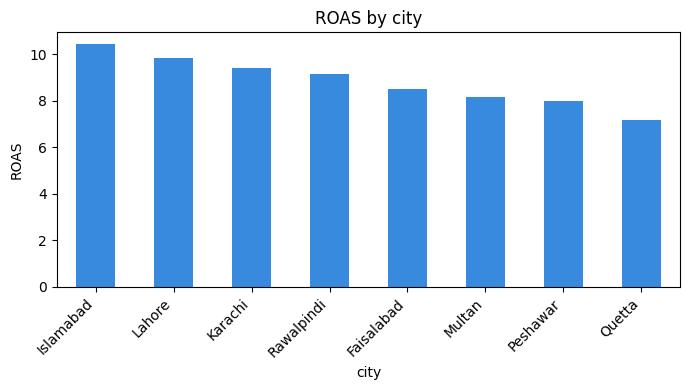

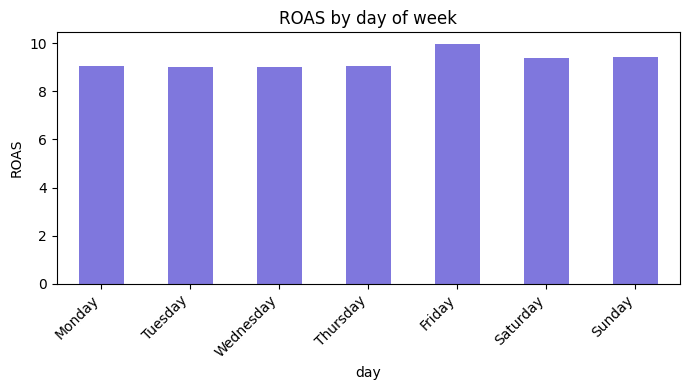

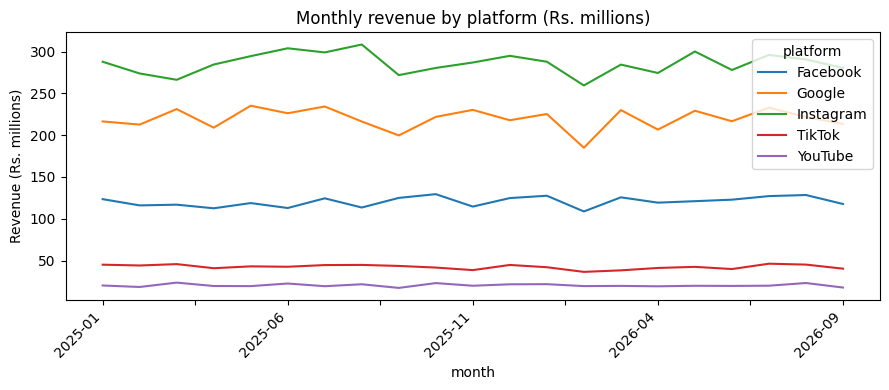

In [5]:
import matplotlib.pyplot as plt

def bar(series, title, ylabel, color="#1D9E75"):
    series.plot(kind="bar", figsize=(7, 4), title=title, color=color)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

plat = summarize(df, "platform").sort_values("ROAS", ascending=False)
bar(plat["ROAS"], "ROAS by platform (revenue per Rs. 1 spent)", "ROAS")

share = pd.DataFrame({"Spend share %": plat.spend / plat.spend.sum() * 100,
                      "Revenue share %": plat.revenue / plat.revenue.sum() * 100})
share.plot(kind="bar", figsize=(7, 4), title="Spend share vs revenue share by platform",
           color=["#BA7517", "#1D9E75"])
plt.ylabel("Percent")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

bar(plat["CPA"].sort_values(), "CPA by platform (Rs. per conversion, lower is better)", "CPA (Rs.)", "#D85A30")
bar(summarize(df, "city").sort_values("ROAS", ascending=False)["ROAS"], "ROAS by city", "ROAS", "#378ADD")
bar(summarize(df, "day").reindex(order)["ROAS"], "ROAS by day of week", "ROAS", "#7F77DD")

df["month"] = df.date.dt.to_period("M").astype(str)
trend = df.pivot_table(index="month", columns="platform", values="revenue", aggfunc="sum") / 1e6
trend.plot(figsize=(9, 4), title="Monthly revenue by platform (Rs. millions)")
plt.ylabel("Revenue (Rs. millions)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [6]:
import csv
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, LongType, DoubleType

def run_pandas(path):
    cols = ["platform", "impressions", "clicks", "spend", "conversions", "revenue"]
    d = pd.read_csv(path, usecols=cols)
    return d.groupby("platform").sum()

def mapper(row):
    return row[2], (int(row[3]), int(row[4]), float(row[5]), int(row[6]), float(row[7]))

def combine(pairs):
    acc = {}
    for k, v in pairs:
        if k in acc:
            a = acc[k]
            acc[k] = (a[0] + v[0], a[1] + v[1], a[2] + v[2], a[3] + v[3], a[4] + v[4])
        else:
            acc[k] = v
    return acc

def run_mapreduce(path, chunk_lines=200_000):
    partials = []
    with open(path, newline="") as f:
        reader = csv.reader(f)
        next(reader)
        buf = []
        for row in reader:
            buf.append(mapper(row))                      # MAP
            if len(buf) >= chunk_lines:
                partials.extend(combine(buf).items())    # COMBINE
                buf = []
        if buf:
            partials.extend(combine(buf).items())
    shuffled = {}                                        # SHUFFLE
    for k, v in partials:
        shuffled.setdefault(k, []).append(v)
    result = {k: tuple(map(sum, zip(*vals))) for k, vals in shuffled.items()}   # REDUCE
    return pd.DataFrame.from_dict(result, orient="index",
        columns=["impressions", "clicks", "spend", "conversions", "revenue"])

spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .appName("AdBenchmark").getOrCreate())

schema = StructType([
    StructField("date", StringType()), StructField("campaign", StringType()),
    StructField("platform", StringType()), StructField("impressions", LongType()),
    StructField("clicks", LongType()), StructField("spend", DoubleType()),
    StructField("conversions", LongType()), StructField("revenue", DoubleType()),
    StructField("age", StringType()), StructField("gender", StringType()),
    StructField("city", StringType()), StructField("device", StringType()),
])

def run_spark(path):
    sdf = spark.read.csv(path, header=True, schema=schema)
    rows = (sdf.groupBy("platform")
               .agg(F.sum("impressions").alias("impressions"), F.sum("clicks").alias("clicks"),
                    F.sum("spend").alias("spend"), F.sum("conversions").alias("conversions"),
                    F.sum("revenue").alias("revenue")).collect())
    return pd.DataFrame([r.asDict() for r in rows]).set_index("platform")

pth = "data/ads_10000.csv"
run_spark(pth)   # warm-up
checks = {}
for name, fn in [("Pandas", run_pandas), ("MapReduce", run_mapreduce), ("Spark", run_spark)]:
    r = fn(pth).sort_index()
    checks[name] = (r.revenue / r.spend).round(4)
print("ROAS per platform from each method (must be identical):")
print(pd.DataFrame(checks))

ROAS per platform from each method (must be identical):
           Pandas  MapReduce  Spark
Facebook     8.15       8.15   8.15
Google       8.41       8.41   8.41
Instagram   13.60      13.60  13.60
TikTok       7.03       7.03   7.03
YouTube      3.28       3.28   3.28


     10,000 records | Pandas    |    0.03 sec
     10,000 records | MapReduce |    0.07 sec
     10,000 records | Spark     |    1.76 sec
    100,000 records | Pandas    |    0.41 sec
    100,000 records | MapReduce |    1.32 sec
    100,000 records | Spark     |    1.36 sec
  1,000,000 records | Pandas    |    1.42 sec
  1,000,000 records | MapReduce |    4.43 sec
  1,000,000 records | Spark     |    5.02 sec
 10,000,000 records | Pandas    |   16.04 sec
 10,000,000 records | MapReduce |   50.10 sec
 10,000,000 records | Spark     |   27.99 sec

BENCHMARK RESULTS (seconds)
          Pandas  MapReduce  Spark Fastest
records                                   
10000       0.03       0.07   1.76  Pandas
100000      0.41       1.32   1.36  Pandas
1000000     1.42       4.43   5.02  Pandas
10000000   16.04      50.10  27.99  Pandas


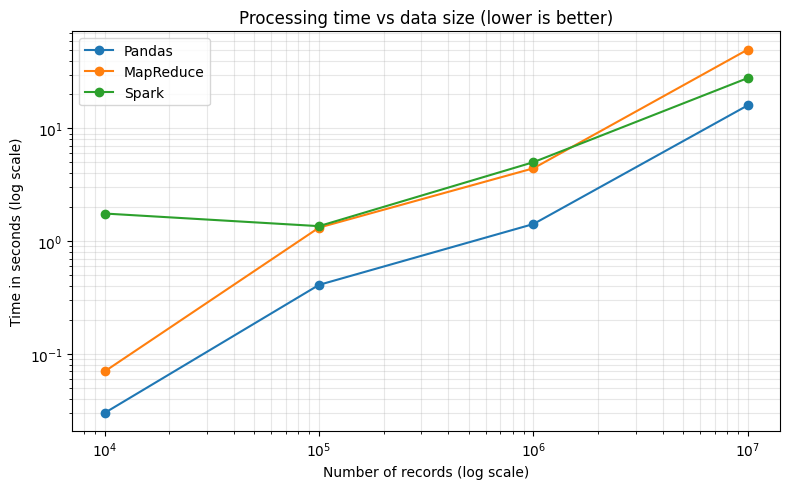

In [7]:
import matplotlib.pyplot as plt

sizes = [10_000, 100_000, 1_000_000, 10_000_000]
rows = []
for n in sizes:
    path = f"data/ads_{n}.csv"
    rec_ = {"records": n}
    for name, fn in [("Pandas", run_pandas), ("MapReduce", run_mapreduce), ("Spark", run_spark)]:
        t = time.perf_counter()
        fn(path)
        rec_[name] = round(time.perf_counter() - t, 2)
        print(f"{n:>11,} records | {name:<9} | {rec_[name]:7.2f} sec", flush=True)
    rows.append(rec_)

bench = pd.DataFrame(rows).set_index("records")
bench["Fastest"] = bench[["Pandas", "MapReduce", "Spark"]].idxmin(axis=1)
bench.to_csv("benchmark_results.csv")
print("\nBENCHMARK RESULTS (seconds)")
print(bench)

ax = bench[["Pandas", "MapReduce", "Spark"]].plot(marker="o", figsize=(8, 5), logx=True, logy=True,
    title="Processing time vs data size (lower is better)")
ax.set_xlabel("Number of records (log scale)")
ax.set_ylabel("Time in seconds (log scale)")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

BUDGET RECOMMENDATION FOR THE NEXT Rs. 1,000,000
           Historical ROAS  Adjusted ROAS  Current share %  Recommended share %  Budget (Rs.)
Instagram            13.68          13.68            27.84                40.00    400,000.00
Google                8.40           8.40            35.48                32.97    329,692.19
Facebook              7.94           7.94            20.20                16.77    167,731.38
TikTok                7.07           7.07             8.00                 5.26     52,576.43
YouTube               3.25           3.41             8.48                 5.00     50,000.00

WHERE SHOULD WE SPEND THE NEXT Rs. 10 LAKH?
  Instagram: 40%  (Rs. 400,000)
  Google: 33%  (Rs. 330,000)
  Facebook: 17%  (Rs. 170,000)
  TikTok: 5%  (Rs. 50,000)
  YouTube: 5%  (Rs. 50,000)

EXPECTED REVENUE FROM Rs. 10 LAKH (model-based)
  Current split : Rs. 9,249,506
  Equal split   : Rs. 8,401,487
  Recommended   : Rs. 9,582,185  (+3.6% vs current)

SHARE % UNDER DIFFERENT ASSUM

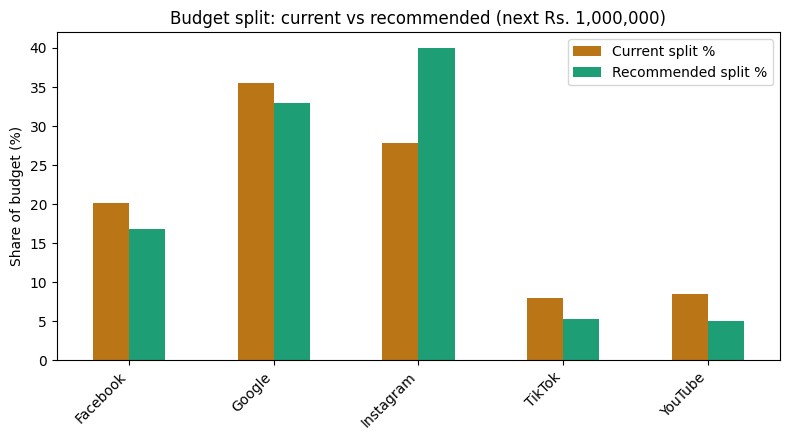

In [8]:
from scipy.optimize import minimize
import matplotlib.pyplot as plt

BUDGET = 1_000_000
ELASTICITY = 0.5
MIN_SHARE, MAX_SHARE = 0.05, 0.40
SENT_WEIGHT = 0.25

hist = (pd.read_csv("data/ads_1000000.csv",
                    usecols=["platform", "impressions", "clicks", "spend", "conversions", "revenue"])
          .groupby("platform").sum())
hist["CTR_%"] = hist.clicks / hist.impressions * 100
hist["CPA"] = hist.spend / hist.conversions
hist["ROAS"] = hist.revenue / hist.spend
hist["spend_share"] = hist.spend / hist.spend.sum()

# Link with Project 1: Khaadi comments were 42% positive and 22% negative
NET_SENTIMENT = {"YouTube": (42 - 22) / 100}
sent_factor = pd.Series({p_: 1 + SENT_WEIGHT * NET_SENTIMENT.get(p_, 0.0) for p_ in hist.index})
hist["adj_ROAS"] = hist.ROAS * sent_factor

plats = list(hist.index)
x0 = hist.spend_share.values * BUDGET

def revenue_model(shares, roas, b):
    x = np.asarray(shares) * BUDGET
    return roas * x0 * (x / x0) ** b

def allocate(b, roas):
    res = minimize(lambda s: -revenue_model(s, roas, b).sum() / BUDGET,
                   np.full(len(plats), 1 / len(plats)), method="SLSQP",
                   bounds=[(MIN_SHARE, MAX_SHARE)] * len(plats),
                   constraints=[{"type": "eq", "fun": lambda s: s.sum() - 1}])
    return res.x

best = allocate(ELASTICITY, hist.adj_ROAS.values)
current_rev = revenue_model(hist.spend_share.values, hist.adj_ROAS.values, ELASTICITY).sum()
equal_rev = revenue_model(np.full(len(plats), 0.2), hist.adj_ROAS.values, ELASTICITY).sum()
best_rev = revenue_model(best, hist.adj_ROAS.values, ELASTICITY).sum()

rec = pd.DataFrame({
    "Historical ROAS": hist.ROAS, "Adjusted ROAS": hist.adj_ROAS,
    "Current share %": hist.spend_share * 100, "Recommended share %": best * 100,
    "Budget (Rs.)": best * BUDGET}, index=plats).sort_values("Recommended share %", ascending=False)

print("BUDGET RECOMMENDATION FOR THE NEXT Rs. 1,000,000")
print(rec)

pct = np.round(rec["Recommended share %"].values).astype(int)
pct[0] += 100 - pct.sum()
print("\nWHERE SHOULD WE SPEND THE NEXT Rs. 10 LAKH?")
for name, p_ in zip(rec.index, pct):
    print(f"  {name}: {p_}%  (Rs. {p_ * BUDGET / 100:,.0f})")

print("\nEXPECTED REVENUE FROM Rs. 10 LAKH (model-based)")
print(f"  Current split : Rs. {current_rev:,.0f}")
print(f"  Equal split   : Rs. {equal_rev:,.0f}")
print(f"  Recommended   : Rs. {best_rev:,.0f}  ({(best_rev / current_rev - 1) * 100:+.1f}% vs current)")
rec.to_csv("budget_recommendation.csv")

sens = pd.DataFrame({f"elasticity {b}": allocate(b, hist.adj_ROAS.values) * 100
                     for b in [0.3, 0.5, 0.7]}, index=plats).round(1)
no_sent = pd.Series(allocate(ELASTICITY, hist.ROAS.values) * 100, index=plats).round(1)
print("\nSHARE % UNDER DIFFERENT ASSUMPTIONS")
print(sens)
print("\nSHARE % WITHOUT THE SENTIMENT ADJUSTMENT")
print(no_sent)

cmp = pd.DataFrame({"Current split %": hist.spend_share * 100,
                    "Recommended split %": best * 100}, index=plats)
cmp.plot(kind="bar", figsize=(8, 4.5), color=["#BA7517", "#1D9E75"],
         title="Budget split: current vs recommended (next Rs. 1,000,000)")
plt.ylabel("Share of budget (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
import shutil, os
from google.colab import files

os.makedirs("project_files", exist_ok=True)
for f in ["data/ads_10000.csv", "data/ads_100000.csv", "benchmark_results.csv",
          "budget_recommendation.csv", "platform_kpi.csv", "campaign_kpi.csv"]:
    shutil.copy(f, "project_files/")
shutil.make_archive("project_files", "zip", "project_files")
files.download("project_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>